In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
import os
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten,Dense,Activation,Conv2D,MaxPooling2D,Dropout

In [ ]:
datadir='/content/drive/MyDrive/train'

In [ ]:
base_dir = '/content/drive/MyDrive/train'
batch_size = 32
img_height = 256
img_width = 256
import tensorflow as tf
training_set = tf.keras.utils.image_dataset_from_directory(
  base_dir,
  label_mode="int",
  validation_split=0.1,
  subset="training",
  seed=100,
  image_size=(img_height, img_width),
  batch_size=batch_size)

Found 1199 files belonging to 3 classes.
Using 1080 files for training.


In [ ]:
validation_set = tf.keras.utils.image_dataset_from_directory(
  base_dir,
  validation_split=0.1,
  subset="validation",
  seed=100,
  image_size=(img_height, img_width),
  batch_size=batch_size)

Found 1199 files belonging to 3 classes.
Using 119 files for validation.


In [ ]:
class_names = training_set.class_names
print(class_names)

['covid', 'normal', 'virus']


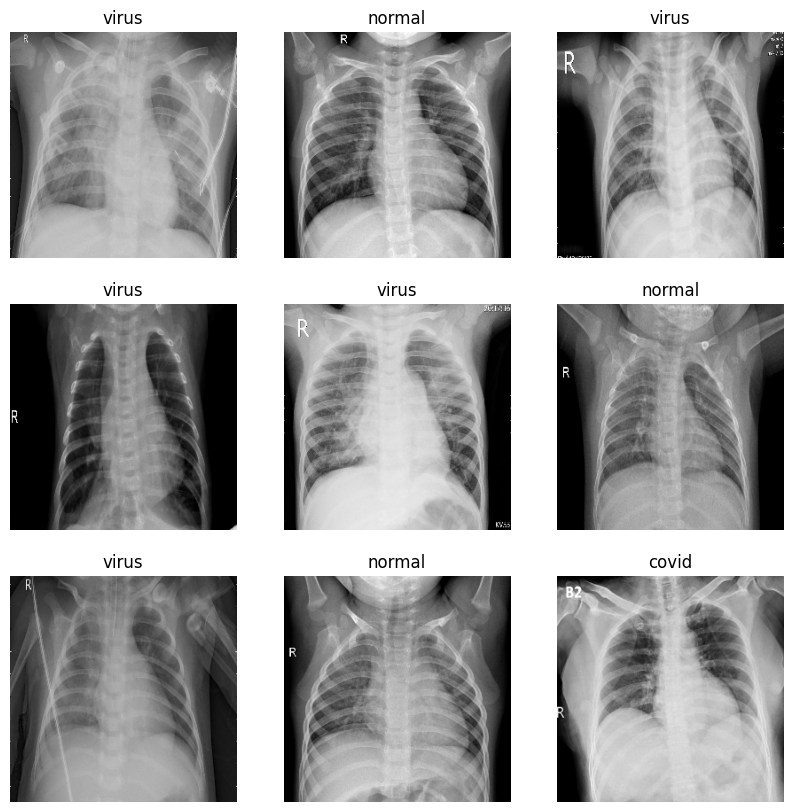

In [ ]:
plt.figure(figsize=(10, 10))
for images, labels in training_set.take(1):
  for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(class_names[labels[i]])
    plt.axis("off")

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

training_ds = training_set.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
validation_ds = validation_set.cache().prefetch(buffer_size=AUTOTUNE)

In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

data_augmentation = keras.Sequential(
  [
    layers.RandomFlip("horizontal",
                      input_shape=(img_height,
                                  img_width,
                                  3)),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
  ]
)

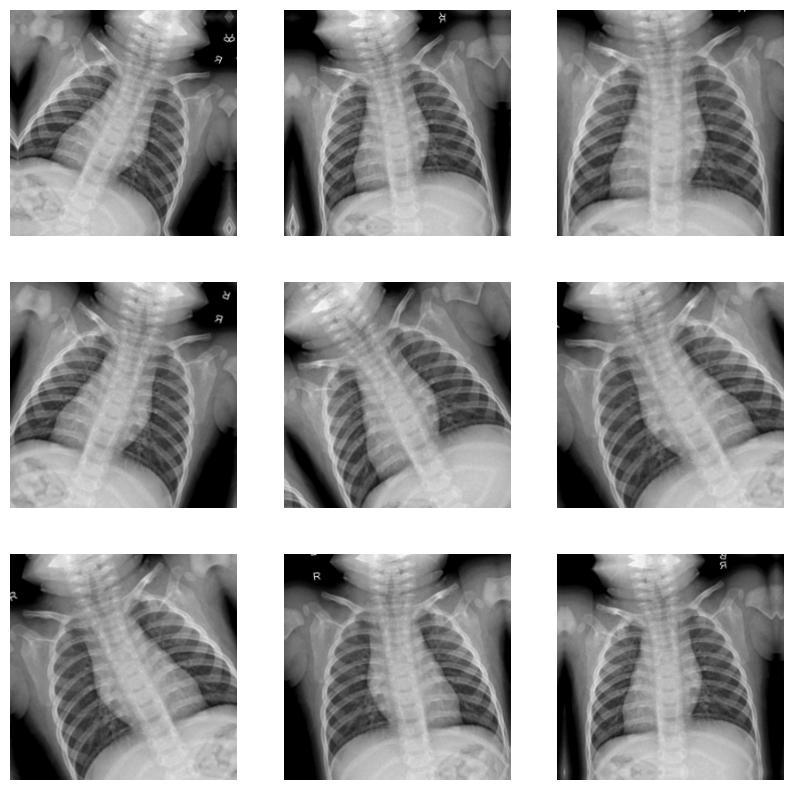

In [ ]:
plt.figure(figsize=(10, 10))
for images, _ in training_set.take(1):
  for i in range(9):
    augmented_images = data_augmentation(images)
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(augmented_images[0].numpy().astype("uint8"))
    plt.axis("off")

In [ ]:
model = keras.Sequential([
    data_augmentation,
    layers.Rescaling(1./255),
    layers.Conv2D(filters=32,kernel_size=(3,3),activation='relu'),
    layers.MaxPooling2D(pool_size=(2,2)),

    layers.Conv2D(filters=32,kernel_size=(3,3), activation='relu'),
    layers.MaxPooling2D(pool_size=(2,2)),
    layers.Dropout(0.25),

    layers.Conv2D(filters=64,kernel_size=(3,3), activation='relu'),
    layers.MaxPooling2D(pool_size=(2,2)),
    layers.Dropout(0.25),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.25),
    layers.Dense(len(class_names), activation='softmax')])

In [ ]:
model.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(),
               metrics=['accuracy'])

In [ ]:
callback = tf.keras.callbacks.EarlyStopping(monitor='loss', patience=3)
epochs=100
history = model.fit(training_set,validation_data=validation_set, epochs=epochs, callbacks=[callback])

Epoch 1/100
34/34 [==============================] - 162s 5s/step - loss: 1.5050 - accuracy: 0.3880 - val_loss: 0.9467 - val_accuracy: 0.6218
Epoch 2/100
34/34 [==============================] - 16s 368ms/step - loss: 0.8419 - accuracy: 0.5991 - val_loss: 0.6523 - val_accuracy: 0.5966
Epoch 3/100
34/34 [==============================] - 15s 350ms/step - loss: 0.6819 - accuracy: 0.6815 - val_loss: 0.6041 - val_accuracy: 0.8067
Epoch 4/100
34/34 [==============================] - 15s 361ms/step - loss: 0.6061 - accuracy: 0.7454 - val_loss: 0.5305 - val_accuracy: 0.7647
Epoch 5/100
34/34 [==============================] - 15s 342ms/step - loss: 0.5639 - accuracy: 0.7426 - val_loss: 0.4401 - val_accuracy: 0.8235
Epoch 6/100
34/34 [==============================] - 15s 363ms/step - loss: 0.5184 - accuracy: 0.7991 - val_loss: 0.4771 - val_accuracy: 0.7983
Epoch 7/100
34/34 [==============================] - 16s 358ms/step - loss: 0.4795 - accuracy: 0.8120 - val_loss: 0.4005 - val_accuracy: 0

In [ ]:
loss, accuracy = model.evaluate(validation_set)
print('Accuracy on test dataset:', accuracy)

4/4 [==============================] - 1s 24ms/step - loss: 0.2489 - accuracy: 0.9160
Accuracy on test dataset: 0.9159663915634155


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras.applications import DenseNet201
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam

img_size = 224

base_model = DenseNet201(input_shape=(img_size, img_size, 3), include_top=False, weights='imagenet')

base_model.trainable = False

model2 = Sequential([
    data_augmentation,
    layers.Rescaling(1./255),
    layers.Lambda(lambda x: tf.image.resize(x, (img_size, img_size))),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(len(class_names), activation='softmax')
])

model2.compile(optimizer=Adam(),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model2.build((None, 128, 128, 3))
model2.summary()


74836368/74836368 [==============================] - 0s 0us/step
Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 sequential (Sequential)     (None, 128, 128, 3)       0         
                                                                 
 rescaling_1 (Rescaling)     (None, 128, 128, 3)       0         
                                                                 
 lambda (Lambda)             (None, 224, 224, 3)       0         
                                                                 
 densenet201 (Functional)    (None, 7, 7, 1920)        18321984  
                                                                 
 global_average_pooling2d (  (None, 1920)              0         
 GlobalAveragePooling2D)                                         
                                                                 
 dense_2 (Dense)             (None, 128)               

In [ ]:
callback = tf.keras.callbacks.EarlyStopping(monitor='loss', patience=3)
epochs=100
history = model2.fit(training_set,validation_data=validation_set, epochs=epochs,callbacks=[callback])

Epoch 1/100
34/34 [==============================] - 297s 8s/step - loss: 0.6406 - accuracy: 0.7222 - val_loss: 0.3444 - val_accuracy: 0.8571
Epoch 2/100
34/34 [==============================] - 314s 9s/step - loss: 0.3241 - accuracy: 0.8889 - val_loss: 0.3643 - val_accuracy: 0.8571
Epoch 3/100
34/34 [==============================] - 298s 9s/step - loss: 0.2936 - accuracy: 0.8917 - val_loss: 0.5246 - val_accuracy: 0.8151
Epoch 4/100
34/34 [==============================] - 292s 9s/step - loss: 0.2745 - accuracy: 0.8954 - val_loss: 0.4513 - val_accuracy: 0.8151
Epoch 5/100
34/34 [==============================] - 302s 9s/step - loss: 0.2519 - accuracy: 0.9093 - val_loss: 0.6685 - val_accuracy: 0.7311
Epoch 6/100
34/34 [==============================] - 323s 9s/step - loss: 0.2260 - accuracy: 0.9194 - val_loss: 0.3132 - val_accuracy: 0.8824
Epoch 7/100
34/34 [==============================] - 293s 9s/step - loss: 0.2093 - accuracy: 0.9241 - val_loss: 0.2502 - val_accuracy: 0.8824
Epoch 

In [ ]:
loss, accuracy = model2.evaluate(validation_set)
print('Accuracy on test dataset:', accuracy)

4/4 [==============================] - 53s 13s/step - loss: 0.2200 - accuracy: 0.9160
Accuracy on test dataset: 0.9159663915634155
